<a href="https://colab.research.google.com/github/SriSudiastini/Restorasi-Citra/blob/main/pcd_image.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving Grainy CCTV Traffic Intersection.png to Grainy CCTV Traffic Intersection.png


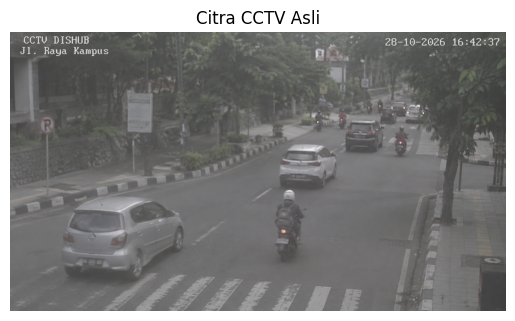

In [4]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import files

# Upload gambar CCTV
uploaded = files.upload()
nama_file = next(iter(uploaded))

# Membaca foto
foto = Image.open(nama_file).convert("RGB")
original_rgb = np.array(foto)

plt.imshow(original_rgb)
plt.title("Citra CCTV Asli")
plt.axis("off")
plt.show()


In [5]:

# Konversi RGB ke HSV
hsv = cv2.cvtColor(
    original_rgb,
    cv2.COLOR_RGB2HSV
)

h, s, v = cv2.split(hsv)

# Meningkatkan saturasi (warna)
s_baru = np.clip(
    s.astype(np.float32) * 1.3,
    0, 255
).astype(np.uint8)

# Meningkatkan kecerahan
v_baru = np.clip(
    v.astype(np.float32) * 1.15,
    0, 255
).astype(np.uint8)

# Memperbaiki kontras lokal dengan CLAHE
clahe = cv2.createCLAHE(
    clipLimit=1.5,
    tileGridSize=(8, 8)
)

v_clahe = clahe.apply(v_baru)

# Menggabungkan HSV kembali
hsv_hasil = cv2.merge([
    h, s_baru, v_clahe
])

# Mengubah ke RGB
hasil_rgb = cv2.cvtColor(
    hsv_hasil,
    cv2.COLOR_HSV2RGB
)

print("Pengolahan warna selesai!")


Pengolahan warna selesai!


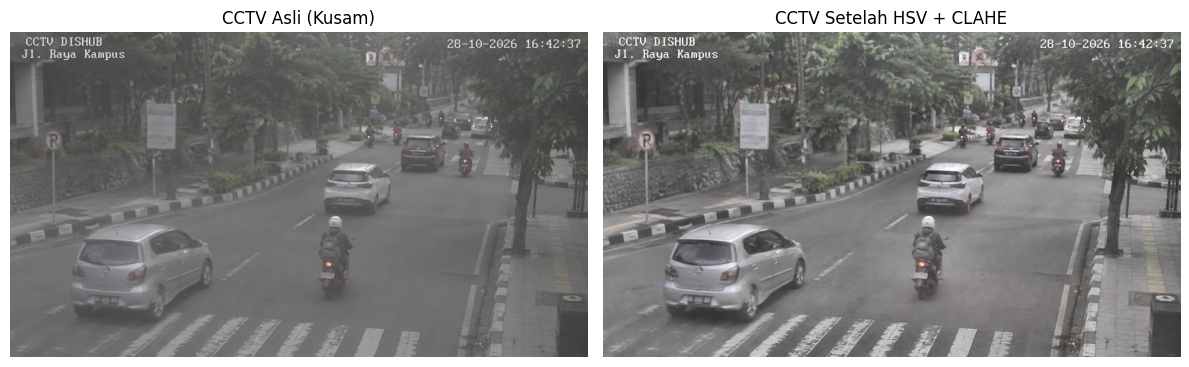

Gambar berhasil disimpan!


In [6]:

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].imshow(original_rgb)
ax[0].set_title("CCTV Asli (Kusam)")
ax[0].axis("off")

ax[1].imshow(hasil_rgb)
ax[1].set_title("CCTV Setelah HSV + CLAHE")
ax[1].axis("off")

plt.tight_layout()
plt.show()

# Simpan hasil
Image.fromarray(hasil_rgb).save(
    "hasil_perbaikan_warna_cctv.png"
)

print("Gambar berhasil disimpan!")
